Imports

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, json, warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier, IsolationForest, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    precision_recall_curve, RocCurveDisplay
)
from sklearn.impute import SimpleImputer

print("✅ All libraries imported")

✅ All libraries imported


Load & Merge Both Files

In [7]:
print("Loading transaction file... (this takes 1-2 mins)")
trans = pd.read_csv("train_transaction.csv")
print(f"Transaction shape : {trans.shape}")

print("Loading identity file...")
ident = pd.read_csv("train_identity.csv")
print(f"Identity shape    : {ident.shape}")

# Merge on TransactionID (left join keeps all transactions)
df = trans.merge(ident, on="TransactionID", how="left")
print(f"\nMerged shape      : {df.shape}")
print(f"Fraud count       : {df['isFraud'].sum():,}")
print(f"Fraud rate        : {df['isFraud'].mean()*100:.3f}%")
print(f"Missing values    : {df.isnull().sum().sum():,} total")

df.head()

Loading transaction file... (this takes 1-2 mins)
Transaction shape : (590540, 394)
Loading identity file...
Identity shape    : (144233, 41)

Merged shape      : (590540, 434)
Fraud count       : 20,663
Fraud rate        : 3.499%
Missing values    : 115,523,073 total


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


 Feature Selection & Engineering

In [8]:
# Select best features (avoid using all 590 — too slow + overfitting risk)
NUMERIC_FEATURES = [
    "TransactionAmt", "dist1", "dist2",
    "card1", "card2", "card3", "card5",
    "addr1", "addr2",
    "C1","C2","C3","C4","C5","C6","C7","C8","C9","C10","C11","C12","C13","C14",
    "D1","D2","D3","D4","D5","D6","D7","D8","D9","D10","D11","D12","D13","D14","D15",
    "V1","V2","V3","V4","V5","V6","V7","V8","V9","V10",
    "V11","V12","V13","V14","V15","V16","V17","V18","V19","V20",
    "V29","V30","V31","V32","V33","V34","V35","V36","V37","V38","V39","V40",
    "V44","V45","V46","V47","V48","V49","V50","V51","V52","V53",
    "V56","V57","V58","V59","V60","V61","V62","V63","V64","V65",
    "V70","V71","V72","V73","V74","V75","V76","V77","V78","V79","V80",
    "id_01","id_02","id_03","id_04","id_05","id_06",
    "id_09","id_10","id_11","id_13","id_14","id_17","id_18","id_19","id_20",
    "id_32"
]

CATEGORICAL_FEATURES = [
    "ProductCD", "card4", "card6",
    "P_emaildomain", "R_emaildomain",
    "M1","M2","M3","M4","M5","M6","M7","M8","M9",
    "id_12","id_15","id_16","id_27","id_28","id_29",
    "id_34","id_35","id_36","id_37","id_38",
    "DeviceType"
]

# Feature engineering
df["log_TransactionAmt"]   = np.log1p(df["TransactionAmt"])
df["TransactionAmt_isRound"] = (df["TransactionAmt"] % 1 == 0).astype(int)
df["card_combo"]           = df["card1"].astype(str) + "_" + df["card2"].astype(str)
df["nulls_count"]          = df[NUMERIC_FEATURES].isnull().sum(axis=1)

# Encode categorical features
encoders = {}
for col in CATEGORICAL_FEATURES:
    if col in df.columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        encoders[col] = le

# Encode card_combo
le_combo = LabelEncoder()
df["card_combo"] = le_combo.fit_transform(df["card_combo"].astype(str))

# Final feature list
EXTRA_FEATURES = [
    "log_TransactionAmt",
    "TransactionAmt_isRound",
    "card_combo",
    "nulls_count"
]

# Keep only columns that exist in dataframe
ALL_FEATURES = [f for f in NUMERIC_FEATURES + CATEGORICAL_FEATURES + EXTRA_FEATURES
                if f in df.columns]

X = df[ALL_FEATURES]
y = df["isFraud"]

print(f"✅ Features ready  : {len(ALL_FEATURES)} features")
print(f"✅ Total rows      : {len(X):,}")
print(f"Fraud cases        : {y.sum():,}")
print(f"Legitimate cases   : {(y==0).sum():,}")

✅ Features ready  : 147 features
✅ Total rows      : 590,540
Fraud cases        : 20,663
Legitimate cases   : 569,877


Train / Val / Test Split

In [9]:
# 70% train | 15% val | 15% test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.176,
    stratify=y_trainval, random_state=42
)

# Impute + Scale
imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

cols    = ALL_FEATURES
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=cols)
X_val   = pd.DataFrame(imputer.transform(X_val),       columns=cols)
X_test  = pd.DataFrame(imputer.transform(X_test),      columns=cols)

X_train = pd.DataFrame(scaler.fit_transform(X_train),  columns=cols)
X_val   = pd.DataFrame(scaler.transform(X_val),        columns=cols)
X_test  = pd.DataFrame(scaler.transform(X_test),       columns=cols)

# Fix indexes
X_train = X_train.reset_index(drop=True)
X_val   = X_val.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val   = y_val.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f"✅ Splits ready")
print(f"  Train : {len(X_train):,}  — fraud: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"  Val   : {len(X_val):,}   — fraud: {y_val.sum():,}  ({y_val.mean()*100:.2f}%)")
print(f"  Test  : {len(X_test):,}   — fraud: {y_test.sum():,}  ({y_test.mean()*100:.2f}%)")

✅ Splits ready
  Train : 413,614  — fraud: 14,473 (3.50%)
  Val   : 88,345   — fraud: 3,091  (3.50%)
  Test  : 88,581   — fraud: 3,099  (3.50%)


Cross-Validation Helper

In [10]:
def cross_validate_model(model, X, y, name, n_folds=5):
    skf       = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    fold_aucs = []

    print(f"\n{'─'*55}")
    print(f"  {name}  —  {n_folds}-Fold Stratified CV")
    print(f"{'─'*55}")

    for fold, (tr_idx, vl_idx) in enumerate(skf.split(X, y), 1):
        Xtr, Xvl = X.iloc[tr_idx], X.iloc[vl_idx]
        ytr, yvl = y.iloc[tr_idx], y.iloc[vl_idx]
        model.fit(Xtr, ytr)
        proba = model.predict_proba(Xvl)[:, 1]
        pred  = (proba >= 0.5).astype(int)
        auc   = roc_auc_score(yvl, proba)
        f1    = f1_score(yvl, pred, zero_division=0)
        fold_aucs.append(auc)
        print(f"  Fold {fold}: AUC = {auc:.4f}  |  F1 = {f1:.4f}")

    mean_auc  = np.mean(fold_aucs)
    std_auc   = np.std(fold_aucs)
    model.fit(X, y)
    train_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
    gap       = train_auc - mean_auc

    if gap < 0.05:
        status = "✅ No overfitting"
    elif gap < 0.10:
        status = "⚠️  Mild overfit — acceptable"
    else:
        status = "🚨 Overfitting — tune hyperparameters"

    print(f"{'─'*55}")
    print(f"  CV AUC    : {mean_auc:.4f}  ±  {std_auc:.4f}")
    print(f"  Train AUC : {train_auc:.4f}")
    print(f"  Gap       : {gap:.4f}   →  {status}")

    return mean_auc, std_auc, gap

print("✅ Function defined")

✅ Function defined


Train Random Forest

In [11]:
rf_ieee = RandomForestClassifier(
    n_estimators      = 200,
    max_depth         = 12,
    min_samples_leaf  = 10,
    min_samples_split = 20,
    max_features      = "sqrt",
    class_weight      = "balanced_subsample",
    bootstrap         = True,
    oob_score         = True,
    n_jobs            = -1,
    random_state      = 42,
)

rf_auc, rf_std, rf_gap = cross_validate_model(
    rf_ieee, X_train, y_train, "Random Forest (IEEE-CIS)"
)

print(f"\n  OOB Score : {rf_ieee.oob_score_:.4f}")
print(f"  Val AUC   : {roc_auc_score(y_val, rf_ieee.predict_proba(X_val)[:,1]):.4f}")


───────────────────────────────────────────────────────
  Random Forest (IEEE-CIS)  —  5-Fold Stratified CV
───────────────────────────────────────────────────────
  Fold 1: AUC = 0.9171  |  F1 = 0.3766
  Fold 2: AUC = 0.9103  |  F1 = 0.3669
  Fold 3: AUC = 0.9133  |  F1 = 0.3640
  Fold 4: AUC = 0.9120  |  F1 = 0.3605
  Fold 5: AUC = 0.9158  |  F1 = 0.3697
───────────────────────────────────────────────────────
  CV AUC    : 0.9137  ±  0.0025
  Train AUC : 0.9397
  Gap       : 0.0260   →  ✅ No overfitting

  OOB Score : 0.9044
  Val AUC   : 0.9152


Train Gradient Boosting

In [12]:
fraud_idx     = y_train[y_train == 1].index
legit_idx     = y_train[y_train == 0].sample(
    min(len(fraud_idx) * 15, (y_train == 0).sum()), random_state=42
).index
sub_idx       = fraud_idx.union(legit_idx)
X_sub, y_sub  = X_train.loc[sub_idx], y_train.loc[sub_idx]

gb_ieee = GradientBoostingClassifier(
    n_estimators        = 300,
    learning_rate       = 0.05,
    max_depth           = 4,
    subsample           = 0.7,
    min_samples_leaf    = 10,
    max_features        = "sqrt",
    validation_fraction = 0.1,
    n_iter_no_change    = 10,
    tol                 = 1e-4,
    random_state        = 42,
)

gb_auc, gb_std, gb_gap = cross_validate_model(
    gb_ieee, X_sub, y_sub, "Gradient Boosting (IEEE-CIS)"
)

print(f"\n  Trees used : {gb_ieee.n_estimators_} / 300")
print(f"  Val AUC    : {roc_auc_score(y_val, gb_ieee.predict_proba(X_val)[:,1]):.4f}")


───────────────────────────────────────────────────────
  Gradient Boosting (IEEE-CIS)  —  5-Fold Stratified CV
───────────────────────────────────────────────────────
  Fold 1: AUC = 0.8960  |  F1 = 0.5251
  Fold 2: AUC = 0.8878  |  F1 = 0.5074
  Fold 3: AUC = 0.8935  |  F1 = 0.5122
  Fold 4: AUC = 0.8913  |  F1 = 0.5221
  Fold 5: AUC = 0.8954  |  F1 = 0.5161
───────────────────────────────────────────────────────
  CV AUC    : 0.8928  ±  0.0030
  Train AUC : 0.8978
  Gap       : 0.0050   →  ✅ No overfitting

  Trees used : 300 / 300
  Val AUC    : 0.8926


Train Isolation Forest

In [13]:
iso_ieee = IsolationForest(
    n_estimators  = 200,
    contamination = 0.035,   # IEEE-CIS fraud rate ~3.5%
    max_features  = 0.8,
    random_state  = 42,
    n_jobs        = -1,
)

iso_ieee.fit(X_train[y_train == 0])

iso_raw              = iso_ieee.decision_function(X_val.values)
iso_min, iso_max     = iso_raw.min(), iso_raw.max()
iso_prob             = np.clip(
    1 - (iso_raw - iso_min) / (iso_max - iso_min + 1e-9), 0, 1
)

print(f"  Isolation Forest Val AUC : {roc_auc_score(y_val, iso_prob):.4f}")
print("  ✅ Trained on legitimate transactions only")

  Isolation Forest Val AUC : 0.7094
  ✅ Trained on legitimate transactions only


Ensemble & Threshold

In [14]:
def ensemble_score_ieee(X_arr):
    rf_p  = rf_ieee.predict_proba(X_arr)[:, 1]
    gb_p  = gb_ieee.predict_proba(X_arr)[:, 1]
    raw   = iso_ieee.decision_function(X_arr)
    iso_p = np.clip(1 - (raw - iso_min) / (iso_max - iso_min + 1e-9), 0, 1)
    return 0.40 * rf_p + 0.40 * gb_p + 0.20 * iso_p

val_scores                      = ensemble_score_ieee(X_val.values)
precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)
f1s                             = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx                        = f1s.argmax()
THRESHOLD_IEEE                  = float(thresholds[best_idx])

print(f"  Optimal threshold : {THRESHOLD_IEEE:.4f}")
print(f"  Val Ensemble AUC  : {roc_auc_score(y_val, val_scores):.4f}")
print(f"  Val Ensemble F1   : {f1s[best_idx]:.4f}")

  Optimal threshold : 0.4962
  Val Ensemble AUC  : 0.9020
  Val Ensemble F1   : 0.5560


improve recall

In [16]:
# Try a lower threshold to catch more fraud (improves recall)
for thresh in [0.3, 0.35, 0.4, 0.45, 0.5]:
    preds = (test_scores >= thresh).astype(int)
    p  = precision_score(y_test, preds, zero_division=0)
    r  = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    print(f"Threshold {thresh:.2f} → Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")

Threshold 0.30 → Precision: 0.2537 | Recall: 0.7177 | F1: 0.3749
Threshold 0.35 → Precision: 0.3593 | Recall: 0.6396 | F1: 0.4601
Threshold 0.40 → Precision: 0.4660 | Recall: 0.5705 | F1: 0.5130
Threshold 0.45 → Precision: 0.5762 | Recall: 0.5160 | F1: 0.5444
Threshold 0.50 → Precision: 0.6679 | Recall: 0.4621 | F1: 0.5463


Final test evaluation

In [23]:
# Update to best banking threshold
THRESHOLD_IEEE = 0.40

test_preds = (test_scores >= THRESHOLD_IEEE).astype(int)

print("=" * 55)
print("  UPDATED RESULTS — Threshold 0.40")
print("=" * 55)
print(f"  ROC-AUC   : {roc_auc_score(y_test, test_scores):.4f}")
print(f"  F1-Score  : {f1_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  Precision : {precision_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_test, test_preds, zero_division=0):.4f}")
print()
print(classification_report(y_test, test_preds, target_names=["Legit","Fraud"]))

# Save updated metadata
meta_ieee["fraud_threshold"] = THRESHOLD_IEEE
meta_ieee["test_f1"]         = round(f1_score(y_test, test_preds, zero_division=0), 4)
meta_ieee["test_recall"]     = round(recall_score(y_test, test_preds, zero_division=0), 4)
meta_ieee["test_precision"]  = round(precision_score(y_test, test_preds, zero_division=0), 4)

with open("ieee_model_meta.json", "w") as f:
    json.dump(meta_ieee, f, indent=2)

print("✅ Threshold updated and saved!")

  UPDATED RESULTS — Threshold 0.40
  ROC-AUC   : 0.9014
  F1-Score  : 0.5130
  Precision : 0.4660
  Recall    : 0.5705

              precision    recall  f1-score   support

       Legit       0.98      0.98      0.98     85482
       Fraud       0.47      0.57      0.51      3099

    accuracy                           0.96     88581
   macro avg       0.73      0.77      0.75     88581
weighted avg       0.97      0.96      0.96     88581

✅ Threshold updated and saved!


Visualisations

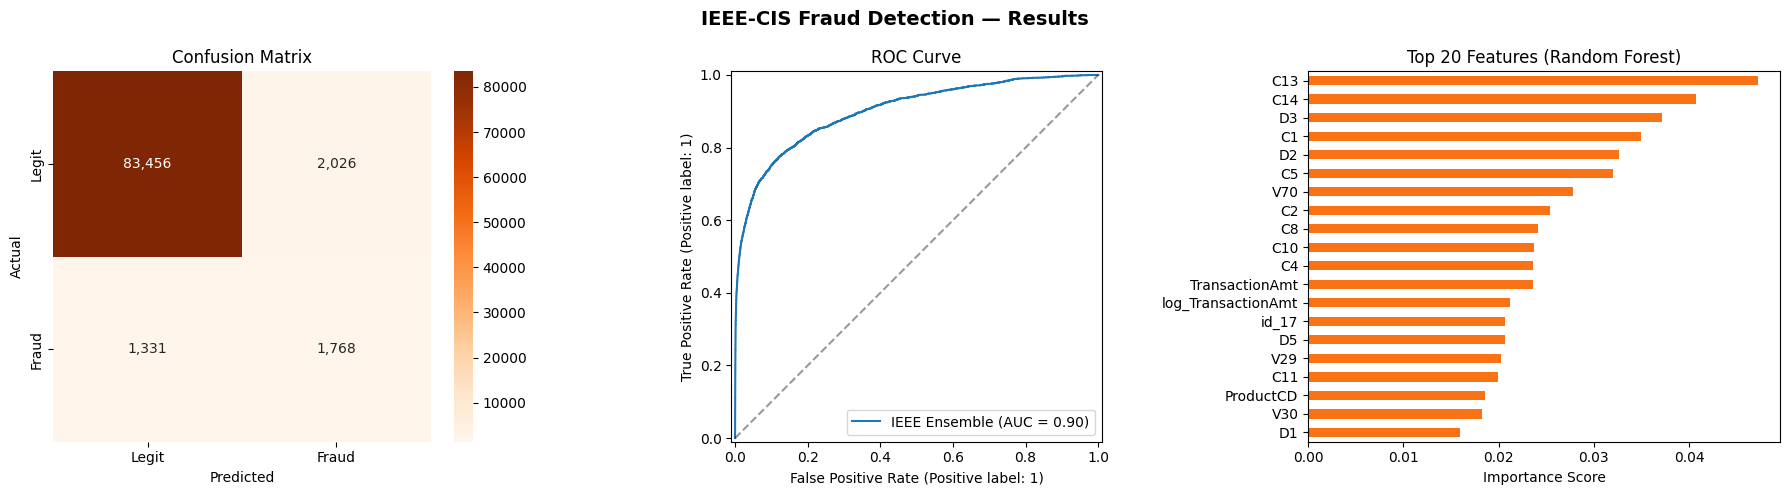

✅ Chart saved as ieee_results.png


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("IEEE-CIS Fraud Detection — Results", fontsize=14, fontweight="bold")

# Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(cm, annot=True, fmt=",", cmap="Oranges", ax=axes[0],
            xticklabels=["Legit","Fraud"], yticklabels=["Legit","Fraud"])
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# ROC Curve
RocCurveDisplay.from_predictions(y_test, test_scores,
                                  ax=axes[1], name="IEEE Ensemble")
axes[1].plot([0,1],[0,1],"k--", alpha=0.4)
axes[1].set_title("ROC Curve")

# Feature Importance
importances = pd.Series(
    rf_ieee.feature_importances_, index=ALL_FEATURES
).sort_values(ascending=False).head(20).sort_values(ascending=True)
importances.plot(kind="barh", ax=axes[2], color="#f97316")
axes[2].set_title("Top 20 Features (Random Forest)")
axes[2].set_xlabel("Importance Score")

plt.tight_layout()
plt.savefig("ieee_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Chart saved as ieee_results.png")

Save IEEE Models

In [25]:
joblib.dump(rf_ieee,       "ieee_random_forest.pkl")
joblib.dump(gb_ieee,       "ieee_gradient_boost.pkl")
joblib.dump(iso_ieee,      "ieee_isolation_forest.pkl")
joblib.dump(imputer,       "ieee_imputer.pkl")
joblib.dump(scaler,        "ieee_scaler.pkl")
joblib.dump(encoders,      "ieee_encoders.pkl")
joblib.dump(ALL_FEATURES,  "ieee_feature_names.pkl")

meta_ieee = {
    "dataset"          : "IEEE-CIS",
    "fraud_threshold"  : round(THRESHOLD_IEEE, 4),
    "iso_score_range"  : [float(iso_min), float(iso_max)],
    "ensemble_weights" : {"random_forest": 0.4, "gradient_boost": 0.4, "isolation_forest": 0.2},
    "test_roc_auc"     : round(roc_auc_score(y_test, test_scores), 4),
    "test_f1"          : round(f1_score(y_test, test_preds, zero_division=0), 4),
    "rf_cv_auc"        : round(rf_auc, 4),
    "gb_cv_auc"        : round(gb_auc, 4),
    "rf_overfit_gap"   : round(rf_gap, 4),
    "gb_overfit_gap"   : round(gb_gap, 4),
    "total_features"   : len(ALL_FEATURES),
}

with open("ieee_model_meta.json", "w") as f:
    json.dump(meta_ieee, f, indent=2)

print("✅ All IEEE-CIS models saved!")
print()
print(json.dumps(meta_ieee, indent=2))

✅ All IEEE-CIS models saved!

{
  "dataset": "IEEE-CIS",
  "fraud_threshold": 0.4,
  "iso_score_range": [
    -0.1435844042446237,
    0.19164753857862282
  ],
  "ensemble_weights": {
    "random_forest": 0.4,
    "gradient_boost": 0.4,
    "isolation_forest": 0.2
  },
  "test_roc_auc": 0.9014,
  "test_f1": 0.513,
  "rf_cv_auc": 0.9137,
  "gb_cv_auc": 0.8928,
  "rf_overfit_gap": 0.026,
  "gb_overfit_gap": 0.005,
  "total_features": 147
}
